# Vec2Text로 비교하는 임베딩 압축 — 간단한 실험

**질문:** 임베딩을 샘플링하고 보간한 뒤에도 원래 문단을 복원할 수 있을까?

한 가지 임베딩 모델인 **GTR**로 처음부터 끝까지 비교한다.
임베딩은 Vec2Text에 들어 있는 GTR 인코더로 만들고, 문단도 같은 Vec2Text 모델로 복원한다.

- 기준: 원문 → GTR 임베딩 → Vec2Text → 복원 문단
- 압축: 원문 → GTR 임베딩 → 정렬·샘플링·보간·역정렬 → Vec2Text → 복원 문단

기본값은 **각각 3문장으로 구성된 짧은 영어 문단 3개**, 샘플 수 **16·64개**이다.
Uniform/Chebyshev × Linear/Cubic의 8개 조건과 압축하지 않은 기준 1개를 비교한다.
원문과 복원 문단을 직접 보고 **Exact Match, BERTScore F1, WER**로 평가한다.

공개 GTR 복원 모델을 사용하는 작은 영어 실험이다. 한국어에 대한 복원 성능으로 해석하지 않는다.
원본 임베딩에서도 Vec2Text가 문단을 틀리게 복원할 수 있으므로 반드시 압축하지 않은 결과와 비교한다.

## 1. Colab 설치 — 이 셀만 먼저 실행
1. GPU 런타임을 선택한다.
2. 아래 설치 셀만 실행한다.
3. 설치가 끝나면 **런타임 → 세션 다시 시작**을 누른다.
4. **설치 셀은 건너뛰고 '2. 설정'부터 차례로 실행**한다.

이후 셀에는 설치 명령이 없다. 설치 셀을 포함한 '모두 실행'은 사용하지 않는다.
모델을 처음 다운로드할 때는 시간이 걸린다. Colab 또는 Linux 환경에서 실행한다.
Vec2Text는 Linux 전용 모듈을 사용하므로 Windows Python에서는 실행하지 않는다.
Linux CPU도 가능하지만 문단 복원은 느리다.

설치 목록의 sentence-transformers는 **Vec2Text 내부 의존성**이다. 임베딩은 Vec2Text의 GTR 인코더로 생성한다.


In [1]:
# 라이브러리 버전은 처음에 한 번만 맞춘다.
%pip install -q numpy scipy pandas matplotlib vec2text==0.0.13 transformers==4.49.0 sentence-transformers==3.4.1 "optimum<2" "datasets<4" "accelerate>=0.26,<2" bert-score jiwer sentencepiece

_packages_installed_in_this_session = True
print("설치 후 세션을 다시 시작하고, 2. 설정부터 실행하세요.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.2/85.2 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.9/275.9 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.8/425.8 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 10.4 MB/s eta 0:00:0

## 2. 설정
SAMPLE_COUNTS는 남길 값의 개수, NUM_STEPS는 Vec2Text의 반복 수정 횟수다.
처음에는 기본값으로 실행하고 필요하면 수정 횟수를 20으로 늘린다.
모든 비교 조건에 동일한 수정 횟수를 적용한다.


In [1]:
if globals().get("_packages_installed_in_this_session", False):
    raise RuntimeError("세션을 다시 시작하고, 설치 셀을 건너뛰고 이 셀부터 실행하세요.")

import sys
if sys.platform == "win32":
    raise RuntimeError("Vec2Text는 Linux 전용 모듈을 사용합니다. 이 파일을 Colab에 업로드해 실행하세요.")

import os
os.environ["USE_TF"] = "0"  # 이 실험은 PyTorch를 사용한다.

from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
import torch
import transformers

assert transformers.__version__ == version("transformers") == "4.49.0", (
    "맨 위 설치 셀 실행 → 세션 다시 시작 → 이 셀 실행 순서로 진행하세요."
)
import vec2text
from bert_score import score
from jiwer import wer
from IPython.display import display

SAMPLE_COUNTS = [16, 64]
NUM_STEPS = 5
assert NUM_STEPS >= 1
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUTPUT_DIR = Path("results_vec2text_paragraphs")
OUTPUT_DIR.mkdir(exist_ok=True)
torch.manual_seed(42)
torch.set_num_threads(4)
print("실행 장치:", DEVICE)
if DEVICE == "cpu":
    print("CPU에서는 느릴 수 있습니다. Colab GPU 런타임을 권장합니다.")


실행 장치: cpu
CPU에서는 느릴 수 있습니다. Colab GPU 런타임을 권장합니다.


## 3. 문단과 GTR 임베딩
각 입력은 서로 이어지는 3문장으로 구성된 짧은 영어 문단이다.
**문단 전체를 한 번에 인코딩하여 임베딩 하나**를 만든다.
복원 결과와 Exact Match, BERTScore, WER도 문단 전체를 기준으로 비교한다.

현재 GTR 복원 체크포인트의 짧은 입력 학습 조건을 고려해 32토큰 이하의 문단부터 시작한다.
사용자가 문단을 수정하면 토큰 수를 출력하고 길이를 검사한다. 32토큰을 넘으면 문단을 짧게 수정한다.
긴 문단을 자동으로 자르거나 요약하지 않는다.
임베딩은 별도로 정규화하지 않고, 복원 모델이 사용하는 인코더 출력을 그대로 사용한다.


In [2]:
paragraphs = [
    (
        "The park was quiet this morning. "
        "A dog ran across the grass. "
        "Its owner followed with a ball."
    ),
    (
        "The student opened her book after lunch. "
        "She read a short chapter. "
        "Then she wrote notes for class."
    ),
    (
        "I made coffee before work. "
        "Rain tapped against the window. "
        "I sat at the table and planned my day."
    ),
]

corrector = vec2text.load_pretrained_corrector("gtr-base")
corrector.model.to(DEVICE).eval()
corrector.inversion_trainer.model.to(DEVICE).eval()
corrector.gen_kwargs["do_sample"] = False

tokenizer = corrector.embedder_tokenizer
lengths = [len(tokenizer(text)["input_ids"]) for text in paragraphs]
print("문단별 토큰 수:", lengths)
assert paragraphs and max(lengths) <= 32, "문단 전체가 32토큰 이하여야 합니다. 문단을 짧게 수정하세요."

tokens = tokenizer(
    paragraphs, return_tensors="pt", padding="max_length",
    max_length=128, truncation=False,
).to(DEVICE)

with torch.no_grad():
    embeddings = corrector.inversion_trainer.call_embedding_model(
        input_ids=tokens["input_ids"],
        attention_mask=tokens["attention_mask"],
    ).float().cpu().numpy()

D = embeddings.shape[1]
assert np.isfinite(embeddings).all()
SAMPLE_COUNTS = [k for k in SAMPLE_COUNTS if 2 <= k <= D]
assert SAMPLE_COUNTS, "2 이상이고 임베딩 차원 이하인 샘플 수가 필요합니다."
index_dtype = np.min_scalar_type(D - 1)
print("임베딩 크기:", embeddings.shape)
print("샘플 수:", SAMPLE_COUNTS)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin.index.json: 0.00B [00:00, ?B/s]

pytorch_model-00001-of-00008.bin:   0%|          | 0.00/193M [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

...

pytorch_model-00005-of-00006.bin:   0%|          | 0.00/187M [00:00<?, ?B/s]

pytorch_model-00006-of-00006.bin:   0%|          | 0.00/37.8M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/6 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/69.0 [00:00<?, ?B/s]

문단별 토큰 수: [24, 24, 26]
임베딩 크기: (3, 768)
샘플 수: [16, 64]


## 4. 샘플링과 보간 함수
Uniform은 일정한 간격으로, Chebyshev-Lobatto는 양 끝을 더 촘촘히 선택한다.
Chebyshev 위치를 반올림해서 중복이 생기면, 가장 넓은 빈 구간의 중간에 점을 추가한다.

보간은 Linear 또는 Natural Cubic Spline을 사용한다. Spline은 단조성을 보장하지 않으므로 값이 튈 수 있다.
보간 후에는 저장한 순열로 **원래 차원 순서를 복원**해야 Vec2Text에 넣을 수 있다.


In [3]:
def sample_indices(dimension, count, sampling):
    # 양 끝점을 포함하는 샘플 위치를 만든다.
    assert 2 <= count <= dimension
    if sampling == "uniform":
        positions = np.linspace(0, dimension - 1, count)
    else:
        angle = np.linspace(0, np.pi, count)
        positions = (dimension - 1) * (1 - np.cos(angle)) / 2
    indices = np.unique(np.rint(positions).astype(int))
    while len(indices) < count:
        gap = np.argmax(np.diff(indices))
        middle = (indices[gap] + indices[gap + 1]) // 2
        indices = np.sort(np.append(indices, middle))
    return indices

def reconstruct(vector, count, sampling, interpolation):
    # 정렬 → 샘플링 → 보간 → 역정렬을 수행한다.
    order = np.argsort(vector)
    sorted_values = vector[order]
    indices = sample_indices(len(vector), count, sampling)
    samples = sorted_values[indices]
    x = np.arange(len(vector))
    if interpolation == "linear":
        interpolated = np.interp(x, indices, samples)
    else:
        interpolated = CubicSpline(indices, samples, bc_type="natural")(x)
    restored = np.empty_like(vector)
    restored[order] = interpolated
    return restored

# 중복 없는 샘플 선택과 전체 차원 복원을 확인한다.
for sampling in ["uniform", "chebyshev"]:
    for count in SAMPLE_COUNTS + [D]:
        indices = sample_indices(D, count, sampling)
        assert len(indices) == len(np.unique(indices)) == count
        assert indices[0] == 0 and indices[-1] == D - 1
    for method in ["linear", "cubic"]:
        restored = reconstruct(embeddings[0], D, sampling, method)
        assert np.allclose(restored, embeddings[0])
print("샘플링·복원 테스트 통과")


샘플링·복원 테스트 통과


## 5. 비교할 임베딩 만들기
Original은 압축하지 않은 기준이다.
나머지 조건의 이름은 U=Uniform, C=Chebyshev, L=Linear, S=Cubic Spline, 뒤의 숫자=샘플 수이다.

저장량은 **float32 샘플 값 + 샘플 위치 + 전체 순열**의 배열 byte 수로 계산한다.
파일 헤더는 제외한 계산이며 실제 파일 크기를 측정한 것은 아니다.
압축하지 않은 기준은 원본 float32 배열만 저장한다.


In [4]:
conditions = {"Original": embeddings}
original_bytes = embeddings[0].nbytes
storage_bytes = {"Original": original_bytes}

for count in SAMPLE_COUNTS:
    for sampling in ["uniform", "chebyshev"]:
        for method in ["linear", "cubic"]:
            prefix = "U" if sampling == "uniform" else "C"
            suffix = "L" if method == "linear" else "S"
            label = f"{prefix}-{suffix}/{count}"
            matrix = np.array([
                reconstruct(vector, count, sampling, method)
                for vector in embeddings
            ], dtype=np.float32)
            assert matrix.shape == embeddings.shape and np.isfinite(matrix).all()
            conditions[label] = matrix
            storage_bytes[label] = 4 * count + (count + D) * index_dtype.itemsize

print("비교 조건:", list(conditions))
print("복원할 문단 수:", len(conditions) * len(paragraphs))


비교 조건: ['Original', 'U-L/16', 'U-S/16', 'C-L/16', 'C-S/16', 'U-L/64', 'U-S/64', 'C-L/64', 'C-S/64']
복원할 문단 수: 27


## 6. Vec2Text로 문단 복원
동일한 Vec2Text 모델과 생성 설정을 모든 조건에 적용한다.
메모리를 적게 쓰도록 한 문단씩 복원한다. 이 셀이 가장 오래 걸릴 수 있다.

복원된 문단은 임베딩에서 **추정한 문단**이다. 정답 문단으로 바꾸거나 띄어쓰기·구두점을 보정하지 않는다.


In [5]:
records = []

for condition, matrix in conditions.items():
    print("복원 중:", condition, flush=True)
    for paragraph_id, vector in enumerate(matrix):
        with torch.no_grad():
            restored_text = vec2text.invert_embeddings(
                embeddings=torch.tensor(vector[None, :], device=DEVICE),
                corrector=corrector,
                num_steps=NUM_STEPS,
                sequence_beam_width=1,
            )[0]
        records.append({
            "condition": condition,
            "paragraph_id": paragraph_id,
            "original": paragraphs[paragraph_id],
            "restored": restored_text,
        })

details = pd.DataFrame(records)
assert len(details) == len(conditions) * len(paragraphs)
# 평가 모델 다운로드가 실패해도 이미 생성한 문단은 파일에 남긴다.
details.to_csv(OUTPUT_DIR / "restored_texts.csv", index=False, encoding="utf-8-sig")
print("문단 복원 완료")


복원 중: Original
복원 중: U-L/16
복원 중: U-S/16
복원 중: C-L/16
복원 중: C-S/16
복원 중: U-L/64
복원 중: U-S/64
복원 중: C-L/64
복원 중: C-S/64
문단 복원 완료


## 7. 세 가지 지표 계산

| 지표 | 계산 방법 | 좋은 방향 |
|---|---|---|
| Exact Match | 공백·대소문자·구두점까지 같으면 1, 아니면 0 | 높을수록 |
| BERTScore F1 | 원문과 복원문의 문맥 기반 토큰 유사도 | 높을수록 |
| WER | 단어 대체·삭제·삽입 수 / 원문 단어 수 | 낮을수록 |

WER은 공백 단위로 계산하고 대소문자·구두점을 유지한다. WER은 1보다 커질 수 있다.
평균 WER은 **문단별 WER의 단순평균**이다. BERTScore는 의미가 완전히 동일하다는 판정이 아니다.


In [6]:
details["Exact Match"] = (details["original"] == details["restored"]).astype(int)
details["WER"] = [
    wer(reference, prediction)
    for reference, prediction in zip(details["original"], details["restored"])
]

# 평가용 BERT 모델은 CPU에서 실행해 GPU 메모리를 아낀다.
_, _, f1 = score(
    cands=details["restored"].tolist(),
    refs=details["original"].tolist(),
    model_type="bert-base-uncased",
    lang="en", device="cpu", batch_size=8, verbose=False,
)
details["BERTScore"] = f1.cpu().numpy()
assert np.isfinite(details[["Exact Match", "BERTScore", "WER"]].to_numpy()).all()

summary = details.groupby("condition", sort=False)[
    ["Exact Match", "BERTScore", "WER"]
].mean()
summary["stored_bytes"] = [storage_bytes[name] for name in summary.index]
summary["reduction_pct"] = 100 * (1 - summary["stored_bytes"] / original_bytes)

details.to_csv(OUTPUT_DIR / "details.csv", index=False, encoding="utf-8-sig")
summary.to_csv(OUTPUT_DIR / "summary.csv", encoding="utf-8-sig")
print("조건별 평균 — Exact Match 0.5는 완전 일치율 50%입니다.")
display(summary.round(4))


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

조건별 평균 — Exact Match 0.5는 완전 일치율 50%입니다.


,Exact Match,BERTScore,WER,stored_bytes,reduction_pct
condition,,,,,
Original,0.0,0.8486,0.6481,3072,0.000
U-L/16,0.0,0.8084,0.7963,1632,46.875
U-S/16,0.0,0.7931,0.7982,1632,46.875
C-L/16,0.0,0.8245,0.7076,1632,46.875
C-S/16,0.0,0.7788,0.8148,1632,46.875
U-L/64,0.0,0.8492,0.7398,1920,37.500
U-S/64,0.0,0.7760,0.8528,1920,37.500
C-L/64,0.0,0.7860,0.7622,1920,37.500
C-S/64,0.0,0.8195,0.5809,1920,37.500


## 8. 원문과 복원 문단 직접 보기
아래 숫자를 0, 1, 2로 바꾸면서 각 문단의 복원 결과를 확인한다.
repr로 출력하므로 따옴표 안의 공백 차이도 확인할 수 있다.
모든 문단의 결과는 details.csv에 저장되어 있다.


In [7]:
SELECTED_PARAGRAPH = 0
assert 0 <= SELECTED_PARAGRAPH < len(paragraphs)
print("원문:", repr(paragraphs[SELECTED_PARAGRAPH]))
selected = details[details["paragraph_id"] == SELECTED_PARAGRAPH]
for _, row in selected.iterrows():
    print(f"\n[{row['condition']}] {repr(row['restored'])}")
    print(
        f"Exact Match={row['Exact Match']}, "
        f"BERTScore={row['BERTScore']:.4f}, WER={row['WER']:.4f}"
    )


원문: 'The park was quiet this morning. A dog ran across the grass. Its owner followed with a ball.'

[Original] "This morning was a quiet . The dog ran across the park grass. The dog's owner followed with a ball and its"
Exact Match=0, BERTScore=0.8149, WER=0.6667

[U-L/16] 'This morning, The park owner was quiet. His dog followed and ran across a ball and onto the grass. '
Exact Match=0, BERTScore=0.7504, WER=0.8889

[U-S/16] 'This morning, the park was quiet. The y’s dog followed its owner. The dog ran across a ball grass on its way'
Exact Match=0, BERTScore=0.7477, WER=1.0556

[C-L/16] 'This morning the park was quiet. The dog followed its owner across a grass. The dog ran across the grass with a ball slicked'
Exact Match=0, BERTScore=0.8151, WER=1.0000

[C-S/16] 'This morning was a quiet day. The dog ran across the park grass. Its owner followed the dog with a ball at . '
Exact Match=0, BERTScore=0.8267, WER=0.6667

[U-L/64] 'This morning was a quiet day. The dog ran across the park

## 9. 결과 그래프
그래프 하나에 세 지표를 나란히 표시한다. 회색 막대는 압축하지 않은 기준이다.
영어 3문단의 평균만 비교하는 작은 탐색 실험이므로 일반적인 성능이나 통계적 유의성을 주장하지 않는다.


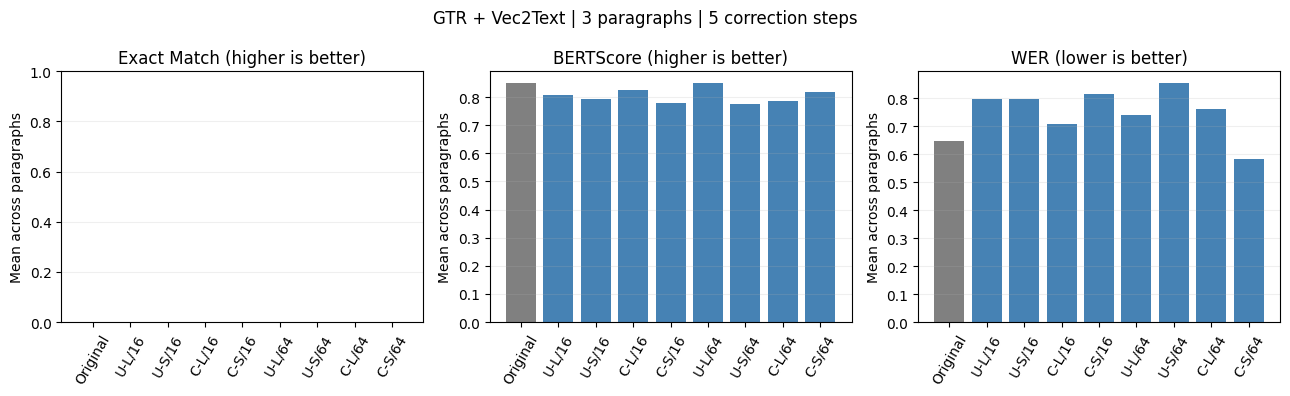

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
labels = summary.index.tolist()
colors = ["gray" if name == "Original" else "steelblue" for name in labels]

for ax, metric in zip(axes, ["Exact Match", "BERTScore", "WER"]):
    ax.bar(labels, summary[metric], color=colors)
    ax.set_title(metric + (" (lower is better)" if metric == "WER" else " (higher is better)"))
    ax.tick_params(axis="x", rotation=60)
    ax.set_ylabel("Mean across paragraphs")
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylim(0, 1)
fig.suptitle(f"GTR + Vec2Text | {len(paragraphs)} paragraphs | {NUM_STEPS} correction steps")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "comparison.png", dpi=200)
plt.show()


## 10. 어떻게 해석하면 될까?
1. **Original부터 확인한다.** 여기서도 문단이 틀린다면 Vec2Text 자체의 복원 한계가 포함된 결과다.
2. 같은 샘플 수에서 U-L, U-S, C-L, C-S를 비교한다.
3. 샘플 수를 늘렸을 때 문단 복원 지표가 좋아지는지 확인한다. 항상 좋아진다고 가정하지 않는다.
4. 높은 문단 유사도와 저장량 감소를 함께 살펴본다. 순열을 저장하므로 샘플 수만큼 저장량이 줄지는 않는다.

수치가 좋아도 직접 출력된 문단을 읽어 사실관계가 바뀌었는지 확인한다.
기준 결과와의 차이는 아래에 자동 계산한다. Exact Match/BERTScore 차이는 양수, WER 차이는 음수일수록 기준보다 좋은 값이다.

참고: [Vec2Text 코드와 사용법](https://github.com/vec2text/vec2text),
[버전 호환성 이슈](https://github.com/vec2text/vec2text/issues/86),
[BERTScore](https://github.com/Tiiiger/bert_score),
[WER](https://jitsi.github.io/jiwer/usage/).


In [9]:
metrics = ["Exact Match", "BERTScore", "WER"]
difference = summary.loc[summary.index != "Original", metrics] - summary.loc["Original", metrics]
print("압축하지 않은 기준 대비 변화:")
display(difference.round(4))
print("결과 저장 폴더:", OUTPUT_DIR.resolve())


압축하지 않은 기준 대비 변화:


,Exact Match,BERTScore,WER
condition,,,
U-L/16,0.0,-0.0402,0.1481
U-S/16,0.0,-0.0555,0.1501
C-L/16,0.0,-0.0241,0.0595
C-S/16,0.0,-0.0697,0.1667
U-L/64,0.0,0.0006,0.0916
U-S/64,0.0,-0.0725,0.2047
C-L/64,0.0,-0.0625,0.1140
C-S/64,0.0,-0.0291,-0.0673


결과 저장 폴더: /content/results_vec2text_paragraphs
